# Exploratory Data Analysis – CA_1, FOODS_3

Goal: understand the demand we will forecast in Phase 1.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_parquet(ROOT / "data" / "processed" / "sales_long.parquet")

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print(df.shape)
df.head()

(1280182, 16)


,item_id,dept_id,cat_id,store_id,sales,date,wm_yr_wk,weekday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,sell_price
0,FOODS_3_001,FOODS_3,FOODS,CA_1,1,2011-01-29,11101,Saturday,1,2011,NaN,NaN,NaN,NaN,0,2.28
1,FOODS_3_001,FOODS_3,FOODS,CA_1,1,2011-01-30,11101,Sunday,1,2011,NaN,NaN,NaN,NaN,0,2.28
2,FOODS_3_001,FOODS_3,FOODS,CA_1,1,2011-01-31,11101,Monday,1,2011,NaN,NaN,NaN,NaN,0,2.28
3,FOODS_3_001,FOODS_3,FOODS,CA_1,1,2011-02-01,11101,Tuesday,2,2011,NaN,NaN,NaN,NaN,1,2.28
4,FOODS_3_001,FOODS_3,FOODS,CA_1,1,2011-02-02,11101,Wednesday,2,2011,NaN,NaN,NaN,NaN,1,2.28


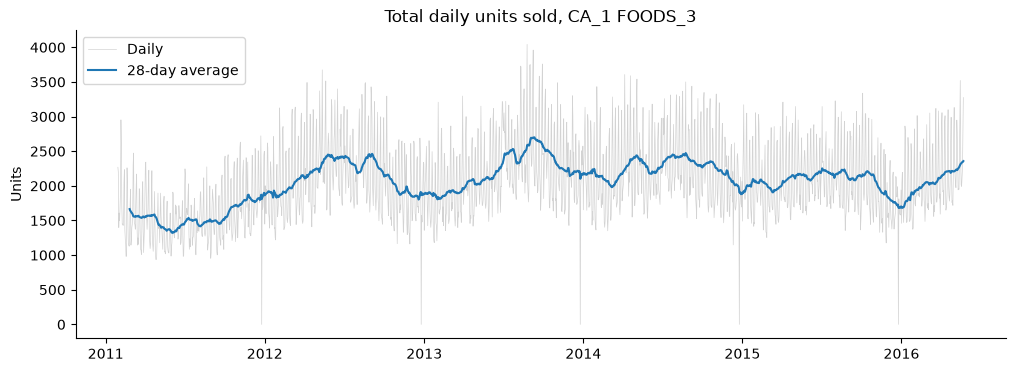

Days with zero total sales: [datetime.date(2011, 12, 25), datetime.date(2012, 12, 25), datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25)]


In [2]:
daily = df.groupby("date")["sales"].sum()

fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, linewidth=0.5, color="lightgray", label="Daily")
ax.plot(daily.index, daily.rolling(28).mean(), color="tab:blue", label="28-day average")
ax.set_title("Total daily units sold, CA_1 FOODS_3")
ax.set_ylabel("Units")
ax.legend()
plt.show()

print("Days with zero total sales:", list(daily[daily == 0].index.date))

Sales show yearly seasonality (summer peak, January low) and drop to zero every 25 December when the store is closed. The level rises through 2011–2012; cell 1b checks whether this comes from new product launches.

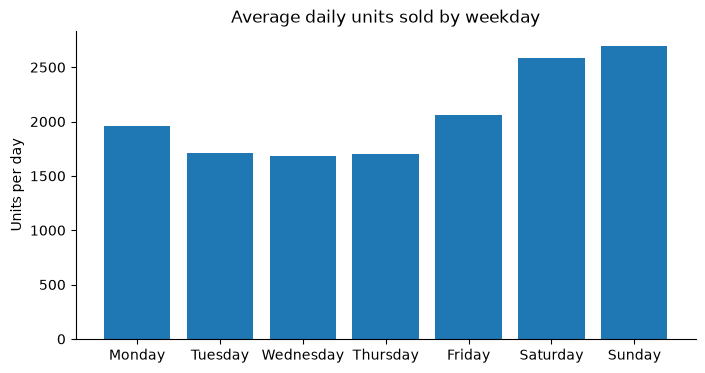

date
Monday       1.17
Tuesday      1.02
Wednesday    1.00
Thursday     1.01
Friday       1.23
Saturday     1.54
Sunday       1.61
Name: sales, dtype: float64


In [3]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = daily.groupby(daily.index.day_name()).mean().reindex(order)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_weekday.index, by_weekday.values, color="tab:blue")
ax.set_title("Average daily units sold by weekday")
ax.set_ylabel("Units per day")
plt.show()

print((by_weekday / by_weekday.min()).round(2))

Weekends sell about 55–60% more than midweek; Wednesday is the weakest day. A 7-day seasonal pattern is essential for forecasting.

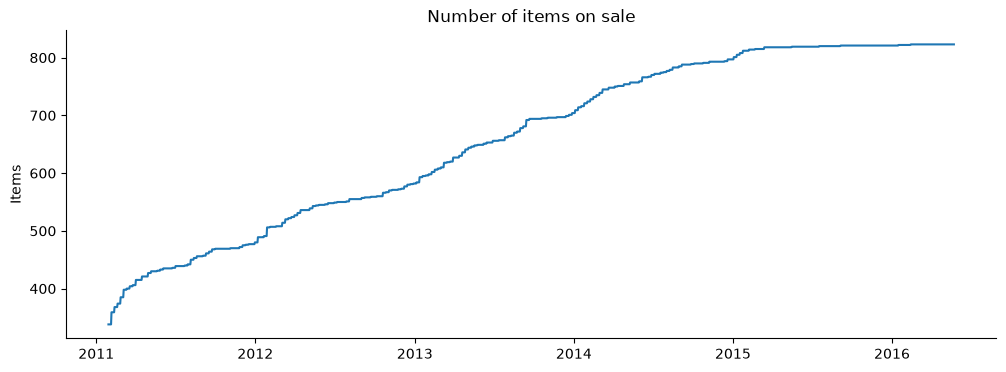

Avg units per active item, 2011: 3.64
Avg units per active item, 2015: 2.51


In [4]:
active_items = df.groupby("date")["item_id"].nunique()

fig, ax = plt.subplots()
ax.plot(active_items.index, active_items.values, color="tab:blue")
ax.set_title("Number of items on sale")
ax.set_ylabel("Items")
plt.show()

per_item = daily / active_items
print("Avg units per active item, 2011:", round(per_item["2011"].mean(), 2))
print("Avg units per active item, 2015:", round(per_item["2015"].mean(), 2))

The number of items on sale grew from about 340 to 820 between 2011 and 2015. Sales per active item fell from 3.64 to 2.51, so the growth in total sales comes from new launches, not higher demand. Forecasts must be made per item.

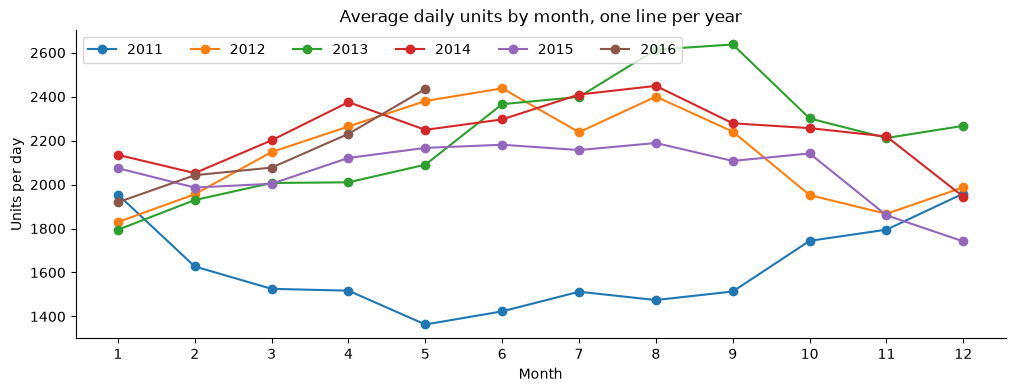

In [5]:
open_days = daily[daily > 0]
monthly = open_days.groupby([open_days.index.year, open_days.index.month]).mean().unstack(0)

fig, ax = plt.subplots()
for year in monthly.columns:
    ax.plot(monthly.index, monthly[year], marker="o", label=str(year))
ax.set_xticks(range(1, 13))
ax.set_title("Average daily units by month, one line per year")
ax.set_xlabel("Month")
ax.set_ylabel("Units per day")
ax.legend(ncol=6)
plt.show()

From 2012 to 2015, sales rise from January to a summer peak and fall towards December, but the swing (about 15–25%) is much weaker than the weekly pattern and varies between years. 2011 is distorted by new items entering.

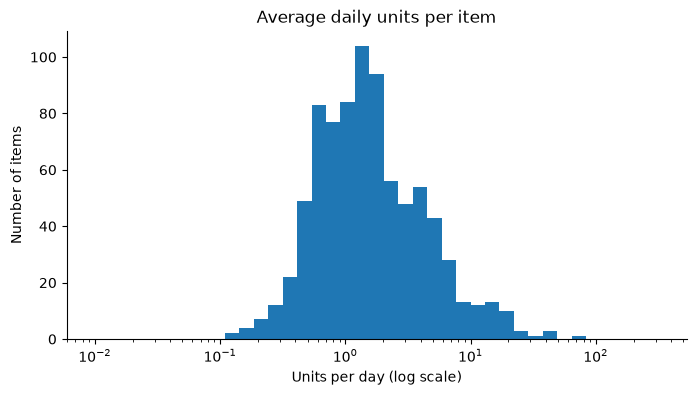

count    823.00
mean       2.88
std        4.85
min        0.13
25%        0.77
50%        1.41
75%        3.02
max       66.39
Name: sales, dtype: float64
Top 10% of items make 49% of all units sold


In [6]:
import numpy as np

item_avg = df.groupby("item_id", observed=True)["sales"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(item_avg[item_avg > 0], bins=np.logspace(-2, 2.5, 40), color="tab:blue")
ax.set_xscale("log")
ax.set_title("Average daily units per item")
ax.set_xlabel("Units per day (log scale)")
ax.set_ylabel("Number of items")
plt.show()

print(item_avg.describe().round(2))
top10 = item_avg.sort_values(ascending=False).head(len(item_avg) // 10)
total = df["sales"].astype("int64").sum()
top_share = df.loc[df["item_id"].isin(top10.index), "sales"].astype("int64").sum() / total
print(f"Top 10% of items make {top_share:.0%} of all units sold")

Most items sell between 0.5 and 5 units per day; the top 10% of items make 49% of all units sold.

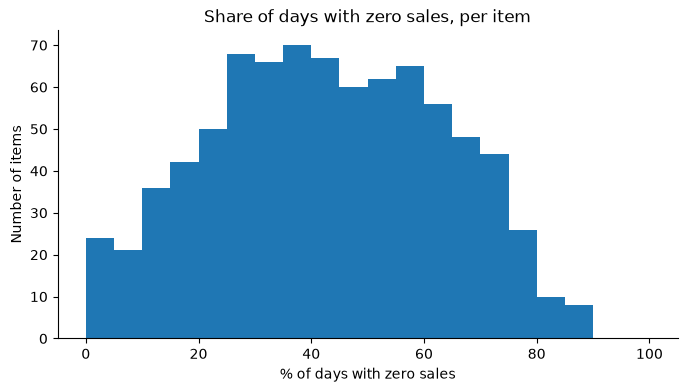

Median item: 43% of days with zero sales
Items with zero sales on more than half of their days: 319 of 823


In [7]:
zero_share = df["sales"].eq(0).groupby(df["item_id"], observed=True).mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(zero_share * 100, bins=20, range=(0, 100), color="tab:blue")
ax.set_title("Share of days with zero sales, per item")
ax.set_xlabel("% of days with zero sales")
ax.set_ylabel("Number of items")
plt.show()

print(f"Median item: {zero_share.median():.0%} of days with zero sales")
print(
    f"Items with zero sales on more than half of their days: "
    f"{(zero_share > 0.5).sum()} of {len(zero_share)}"
)

The median item has zero sales on 43% of days; 319 of 823 items (39%) sell nothing on more than half of their days.

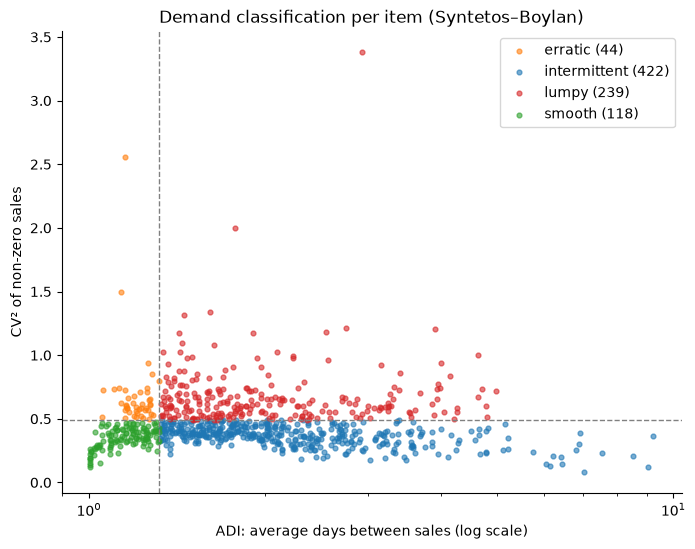

type
intermittent    422
lumpy           239
smooth          118
erratic          44
Name: count, dtype: int64
type
intermittent    51.3
lumpy           29.0
smooth          14.3
erratic          5.3
Name: proportion, dtype: float64


In [8]:
def demand_profile(s: pd.Series) -> pd.Series:
    nonzero = s[s > 0]
    adi = len(s) / len(nonzero) if len(nonzero) > 0 else np.nan
    cv2 = (nonzero.std() / nonzero.mean()) ** 2 if len(nonzero) > 1 else np.nan
    return pd.Series({"adi": adi, "cv2": cv2})


profile = df.groupby("item_id", observed=True)["sales"].apply(demand_profile).unstack()


def classify(row):
    if row["adi"] < 1.32:
        return "smooth" if row["cv2"] < 0.49 else "erratic"
    return "intermittent" if row["cv2"] < 0.49 else "lumpy"


profile["type"] = profile.apply(classify, axis=1)

colors = {
    "smooth": "tab:green",
    "erratic": "tab:orange",
    "intermittent": "tab:blue",
    "lumpy": "tab:red",
}

fig, ax = plt.subplots(figsize=(8, 6))
for kind, group in profile.groupby("type"):
    ax.scatter(
        group["adi"],
        group["cv2"],
        s=12,
        alpha=0.6,
        color=colors[kind],
        label=f"{kind} ({len(group)})",
    )
ax.axvline(1.32, color="gray", linestyle="--", linewidth=1)
ax.axhline(0.49, color="gray", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_title("Demand classification per item (Syntetos–Boylan)")
ax.set_xlabel("ADI: average days between sales (log scale)")
ax.set_ylabel("CV² of non-zero sales")
ax.legend()
plt.show()

print(profile["type"].value_counts())
print((profile["type"].value_counts(normalize=True) * 100).round(1))

80% of items are intermittent (51%) or lumpy (29%); only 14% are smooth. Intermittent-demand methods (Croston, TSB) and zero-friendly metrics (MAE, RMSSE) are essential in Phase 1.

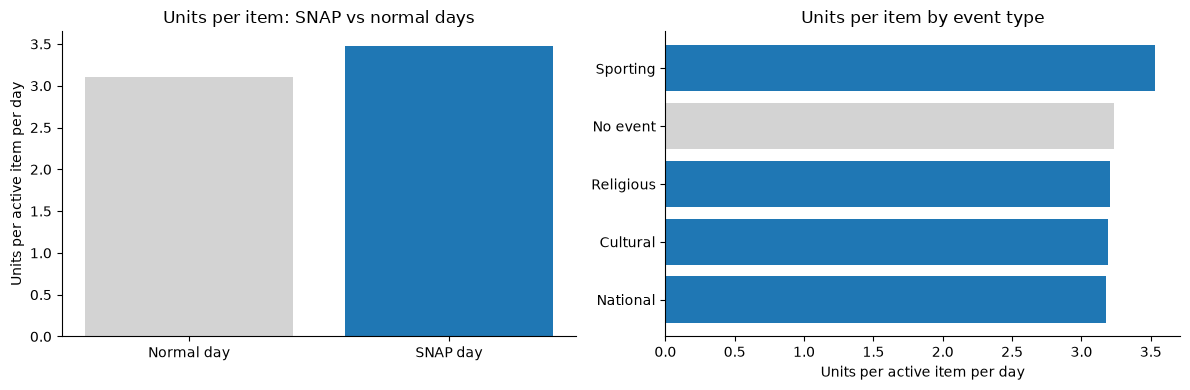

SNAP uplift: +11.8%
event
National     -1.8%
Cultural     -1.2%
Religious    -0.9%
No event     +0.0%
Sporting     +9.3%
Name: per_item, dtype: str


In [9]:
day = df.groupby("date").agg(snap=("snap_CA", "first"), event=("event_type_1", "first"))
day["per_item"] = per_item
day = day[daily > 0]

snap_effect = day.groupby("snap")["per_item"].mean()
event_effect = (
    day.groupby(day["event"].astype("object").fillna("No event"))["per_item"].mean().sort_values()
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(["Normal day", "SNAP day"], snap_effect.values, color=["lightgray", "tab:blue"])
ax1.set_title("Units per item: SNAP vs normal days")
ax1.set_ylabel("Units per active item per day")

bar_colors = ["lightgray" if name == "No event" else "tab:blue" for name in event_effect.index]
ax2.barh(event_effect.index, event_effect.values, color=bar_colors)
ax2.set_title("Units per item by event type")
ax2.set_xlabel("Units per active item per day")
plt.tight_layout()
plt.show()

print(f"SNAP uplift: {snap_effect[1] / snap_effect[0] - 1:+.1%}")
print((event_effect / event_effect["No event"] - 1).map("{:+.1%}".format))

SNAP days increase sales per item by about 12%. Event days themselves show little effect (sporting +9% on few days; others about −1%); the effect is probably on the days before the event.

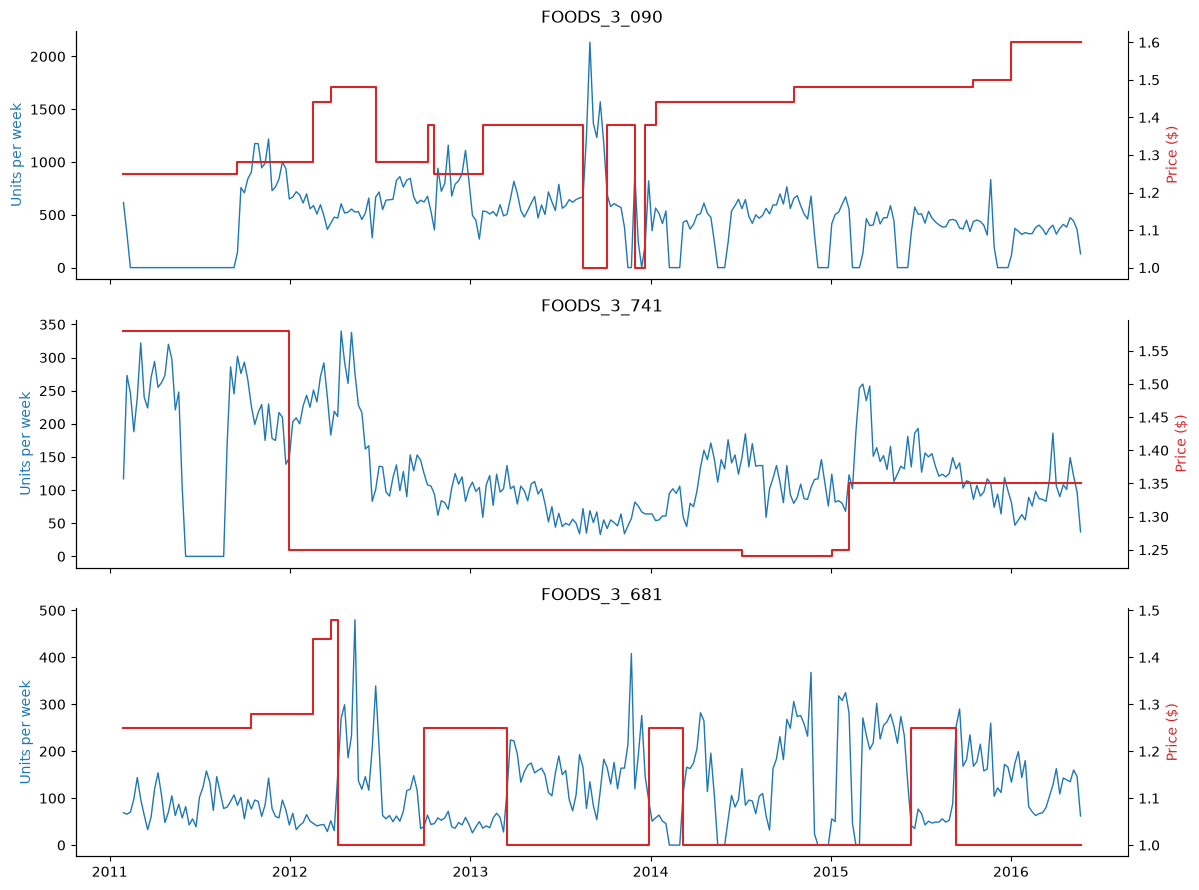

Items selling 2+ units/day with a run of 14+ zero days: 247
item_id
FOODS_3_444    413
FOODS_3_410    385
FOODS_3_657    371
FOODS_3_732    365
FOODS_3_092    364
FOODS_3_054    363
FOODS_3_107    363
FOODS_3_441    361
FOODS_3_587    361
FOODS_3_659    360
Name: sales, dtype: int64


In [10]:
weekly = (
    df.groupby(["item_id", "wm_yr_wk"], observed=True)
    .agg(sales=("sales", "sum"), price=("sell_price", "mean"), date=("date", "min"))
    .reset_index()
)

n_prices = weekly.groupby("item_id", observed=True)["price"].nunique()
candidates = item_avg[n_prices[n_prices >= 4].index].sort_values(ascending=False).head(3).index

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, item in zip(axes, candidates):
    data = weekly[weekly["item_id"] == item]
    ax.plot(data["date"], data["sales"], color="tab:blue", linewidth=1)
    ax.set_ylabel("Units per week", color="tab:blue")
    ax.set_title(item)

    ax_price = ax.twinx()
    ax_price.step(data["date"], data["price"], where="post", color="tab:red", linewidth=1.5)
    ax_price.set_ylabel("Price ($)", color="tab:red")
    ax_price.spines["right"].set_visible(True)
plt.tight_layout()
plt.show()


def longest_zero_run(s: pd.Series) -> int:
    is_zero = s.eq(0)
    run_id = (~is_zero).cumsum()
    return int(is_zero.groupby(run_id).sum().max())


zero_runs = df.groupby("item_id", observed=True)["sales"].apply(longest_zero_run)
suspicious = zero_runs[(zero_runs >= 14) & (item_avg >= 2)]

print(f"Items selling 2+ units/day with a run of 14+ zero days: {len(suspicious)}")
print(suspicious.sort_values(ascending=False).head(10))

Price promotions have a strong effect: FOODS_3_681 sells 3–4× more at $1.00 than at $1.25. Price is not the only driver (FOODS_3_741). Long runs of zero sales in fast-moving items (FOODS_3_090) point to stockouts, not zero demand.

247 of the 295 items selling 2+ units/day (84%) have at least one run of 14+ zero days: 654 runs of 14–60 days (likely stockouts) and 308 runs over 60 days (item likely off the shelf despite a listed price).

## Findings

1. The number of items on sale grew from ~340 to ~820 (2011–2015) while sales per active item fell from 3.64 to 2.51: total growth comes from launches, not demand.
2. Strong weekly pattern: Sunday sells 61% and Saturday 54% more than Wednesday, the weakest day.
3. Weak yearly seasonality (~15–25% swing, summer peak) that varies between years.
4. The median item sells 1.4 units/day; the top 10% of items make 49% of all units sold.
5. 80% of items are intermittent (51%) or lumpy (29%); only 14% are smooth.
6. SNAP days raise sales per item by 11.8%; event days themselves change sales by −2% to +9%.
7. Price cuts have strong effects on some items (3–4× sales at −20% price), but price is not the only driver.
8. 84% of fast-moving items have zero-sales runs of 14+ days: likely stockouts (14–60 days) or items off the shelf (60+ days). These zeros are not real zero demand.

## What this means for next phases

- Forecast per item, never the total.
- Add an `available` flag and exclude zero runs of 14+ days in fast movers from training and evaluation.
- Key benchmark: seasonal naive (7 days).
- Croston/TSB for the ~80% intermittent and lumpy items; ETS/ARIMA mainly for smooth items.
- LightGBM features: weekday, month, SNAP, days to next event, price and price change; Tweedie or Poisson objective.
- Metrics: MAE and RMSSE, not MAPE; report results per demand type.
- Treat 25 December (store closed) separately.